# T03 - GREEKS
## Carlos Santiago Nava Pulido


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd



Una institución financiera diseña tres opciones sobre acciones que actualmente cotizan en $100:

**OPCIÓN A**:
K = 90

T = 1/12

Prima = 12

Delta = 0.85

Vega = 0.05

Theta = -0.10

**OPCIÓN B**:
K = 100

T = 3/12

Prima = 8

Delta = 0.50

Vega = 0.25

Theta = -0.03

**OPCIÓN C**:
K = 120

T = 1

Precio = 5

Delta = 0.20

Vega = 0.40

Theta = -0.01

## PARTE 1: Escenarios de mercado

1. ¿Cuál opción parece más sensible a cambio en el precio de la acción?
- La opción A posee un Delta de .85 (superior al resto)

2. ¿Cuál opción parece más sensible a cambios en volatilidad?
- La opción C posee un Vega de .40

3. ¿Cuál opción parece deteriorarse más rápidamente con el paso del tiempo?
- A se deteriora sustancialmente más rápido que el resto de opciones.

4. ¿Cuál opción parece tener el comportamiento más parecido al de la acción?
- Podría ser la opción A, sobretodo por el delta cercano a 1.

5. ¿Cuál acción parece depender más de que ocurra un evento importante en el futuro?
-  La opción C posee un tiempo de ejercisio más largo, esto lo vuelve más sucpetible a depender del futuro, aunque la opción A posee un Theta más alto así que no estoy seguro




## PARTE 2: Escenarios de mercado

Para cada escenario explica qué opción comprarías y cuál evitarías. Justifica tus respuestas usando tu entendimiento de sensibilidades.

> SUPONDRE CALL POR SU DELTA (+)...

- Escenario A:
Piensas que la acción aumentará gradualmente durante los próximos meses. No crees que vaya a cambiar la volatilidad.

> OPCIÓN A:Aunque está ITM, la prima es de 12 y el periodo es muy corto, considerando baja volatilidad y además que el movimeinto abarcara **meses**; no se compra.

> OPCIÓN B: **Si se compraría**, tenemos 3 meses para ejercer suficinete para captar el movimiento esperado; su vega es relativamente alto lo cual se dicipa con la expectativa y no se tendría problema por la minusvalía del tiempo.

> OPCIÓN C: No se compra, tiene demasiado tiempo de ejercisio.


- Escenario B:
Dentro de dos semanas la empresa anunciará un nuevo producto. No sabes si el precio subirá o bajará, pero esperas un cambio brusco.

> OPCIÓN A: No es una buena opción por el horizonte de movimiento, sería una cobertura cara que solo portege una dirección, además captarías casí toda la perdida en el peor caso; además posee el Vega más resiliente así que no aprobecha sla volatilidad y  sería problema el theta anulando VEGA.

> OPCIÓN B: Aunque es balanceado, no superaría una estrategia Stradle.

>OPCIÓN C: Es mejor opción que A y captas mas de la volatilidad, sin perder por Theta. Es la mejor opción ya que venderías la opción antes de que caiga la volatilidad.


- Escenario C:
Piensas que la acción se mantendrá muy estable.
> OPCIÓN A: No hay mucha información, pero es la que mejor capta el precio, sin embargo ¿estable que refiere?, tenemos una prima adecuada considerando que estamos ITM, necesitamos que el precio se mueva en un tiempo muy corto minimo $2.

> OPCIÓN B: Sigue siendo la más balanceada, pero está ATM, si no se mueve el precio, perdemos la prima.

>OPCIÓN C: No hay volatilidad quee captar, no perderíamos por Theta pero casí no captaríamos el movimiento del precio. Además estamos OTM tendrámos $20 en perdida.


- Escenario D:
Crees que va a haber una caída significativa del precio de la acción

> No compres ninguna, o estarías cvaptando toda la perdida en A, o estarías alejandote de una prima de por si Cara en B y C

- Escenario E:
Crees que el mercado está subestimando la incertidumbre futura,

> Compra la C, misma logica que en el escenario B, pero esta vez tienes como ventaja el tiempo de ejercisio.

### JUSTIFICACIÓN (SUPONGO CALLS):
- ESCENARIO A:

## PARTE 3: Simulación
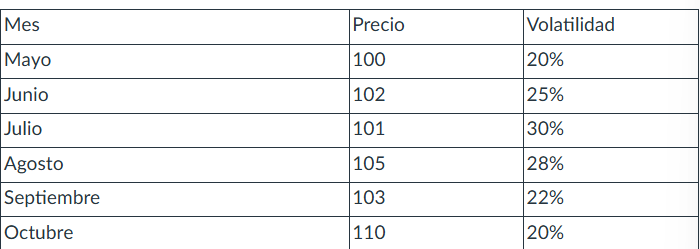

Se tiene que para el día inicial:

r = 5%

K = 100

V0 = 6.8887 (valor de la opción)

Delta = 0.5977

Gamma = 0.02736

Vega = 0.2814

Theta = -8.116 (anualizado)

DONDE...

$$
dS = S_t - S_{t-1}
$$

$$
d\sigma = \sigma_t - \sigma_{t-1}
$$

$$
dt = \frac{1}{12}
$$

$$
V_t = V_{t-1} + \Delta \, dS + \frac{1}{2}\Gamma (dS)^2 + \text{Vega} \, d\sigma + \Theta \, dt
$$


In [7]:
precios = [100, 102,101, 105,103, 110]
sigmas = [.20,.25,.30,.28,.22,.20]
Delta = .5977
Gamma = .0273
Vega = .2814
Theta = -8.116
Valor = [6.887]
dt = 1/12
for i in range(5):
    dS = precios[i+1] - precios[i]
    dSigma = sigmas[i+1] - sigmas[i]
    efecto_vega = Vega * dSigma
    Valor.append(Valor[i] + Delta * dS + .5 * Gamma * (dS **2) +efecto_vega + Theta * dt)

valor_taylor = np.array(Valor)
valor_taylor

array([ 6.887     ,  7.47473667,  6.22842333,  8.155662  ,  6.32164467,
       10.49243333])

### Ahora calcula para cada mes el valor de la call (simula 10000 escenarios) con vencimiento en Octubre utilizando el precio y la volatilidad del mes en curso:

In [8]:
#region función montecarlo
def monte_carlo_option_pricer(S0, K, T, r, sigma, num_simulations, option_type):
    np.random.seed(42)

    dt = T
    drift = (r - 0.5 * sigma**2) * dt
    diffusion = sigma * np.sqrt(dt)

    Z = np.random.normal(0, 1, num_simulations)
    log_returns = drift + diffusion * Z
    price_path = S0 * np.exp(log_returns)
    simulated_prices = price_path

    if option_type == 'call':
        payoffs = np.maximum(0, simulated_prices - K)
    elif option_type == 'put':
        payoffs = np.maximum(0, K - simulated_prices)
    else:
        raise ValueError("option_type debe ser 'call' o 'put'")

    option_price = np.exp(-r * T) * np.mean(payoffs)
    return option_price

#endregion

In [9]:
valores_monte_carlo = [6.8887]
precios = [100, 102,101, 105,103, 110]
sigmas = [.20,.25,.30,.28,.22,.20]
tiempo = [5/12, 4/12, 3/12, 2/12, 1/12, 0]
r = .05
K = 100
for i in range(5):
    price = monte_carlo_option_pricer(precios[i+1],K,tiempo[i+1],r,sigmas[i+1],num_simulations=1000,option_type='call' )
    valores_monte_carlo.append(price)

valores_monte_carlo = np.array(valores_monte_carlo)

## COMPAREMOS:


,GREEKS,BLACK-SCHOLES,SE
Mayo,6.887000,6.888700,0.001700
Junio,7.474737,7.818815,0.344078
Julio,6.228423,7.190103,0.961679
Agosto,8.155662,8.173100,0.017438
Septembre,6.321645,4.643682,1.677963
Octubre,10.492433,10.000000,0.492433


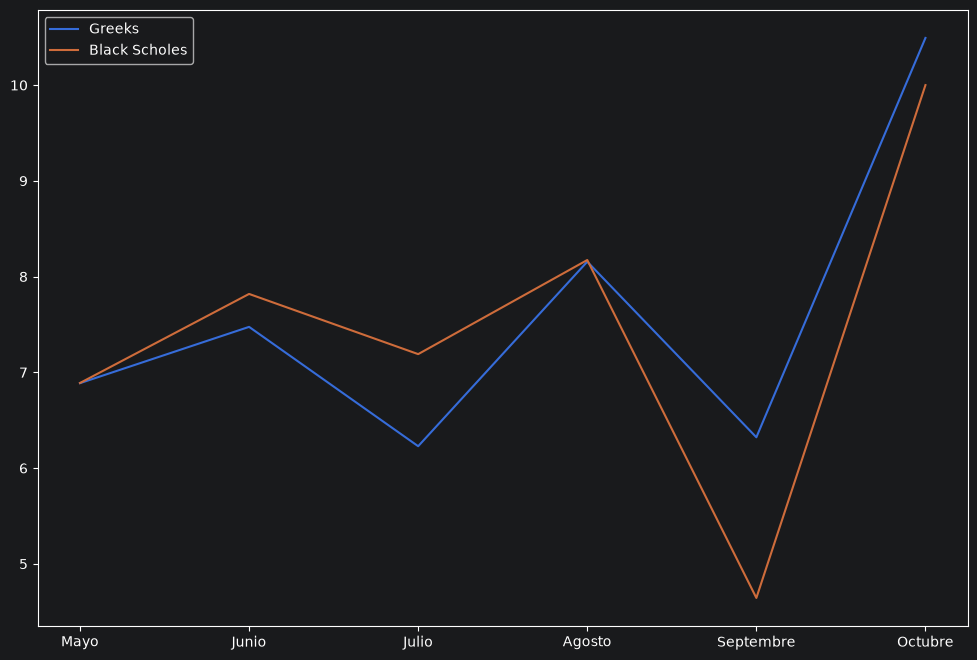

In [10]:
EAbs = valores_monte_carlo - valor_taylor
RES = pd.DataFrame(
    {
        'GREEKS': valor_taylor,
        'BLACK-SCHOLES': valores_monte_carlo,
        'SE': np.abs(EAbs)

    }, index=['Mayo','Junio','Julio','Agosto','Septembre','Octubre']
)
display(RES)

plt.figure(figsize=(12,8))
plt.plot(RES.index,RES['GREEKS'], label='Greeks')
plt.plot(RES.index,RES['BLACK-SCHOLES'], label='Black Scholes')
plt.legend()
plt.show()

1. ¿Los greeks iniciales describen con precisión toda la trayectoria?

No completamente tenemos griegas que no evolucionan, además de que serie de taylo en sí solo funciona cercano al origen.

2. ¿En qué mes apareció el error más grande?

En septiembre

3. ¿Qué factor parece contribuir más al error?

Podría ser el tiempo, pero en escecia es por no actualizar Delta y Gamma

4. ¿Por qué los Greeks funcionan mejor para movimientos pequeños que para movimientos grandes?

EN menor medida porque conforme te acercas a el ejercisio el valor Extrínciso se pierde impacto y te quedas con las Griegas que no cambiaste, realmente es porque Taylor posee $\epsilon$ grnades cuando inyectas valores grandes

5. Si la trayectoria fuera mucho más volátil, ¿esperarías errores menores? ¿por qué?

-No, mientras sea más pequeño se aproximara correctamente.

6. Concluye

Las griegas te dan información para tomar mejoras decisiones y te permite entender que el valor de una opción va más alla de su payofff al tiempo de ejercisio, su prima podría capta más valor con las griegas adecuadas en el momento correcto. El análisis demuestra la necesidad  de recalcular las griegas dinámicamente para evitar desvíos significativos a medida que se aproxima la fecha de ejercicio."